# Pairs Trading: Notebook Demo

Runs the same pipeline as `main.py`, one step per cell, so you can inspect every intermediate result.

## 1. Imports
`%matplotlib inline` makes charts appear inside the notebook.

In [1]:
from pairs_trading import plots
from pairs_trading.config import DEFAULT_UNIVERSE, Settings
from pairs_trading.data import download_prices
from pairs_trading.pair_selection import find_cointegrated_pairs
from pairs_trading.pipeline import run_pair

%matplotlib inline
settings = Settings()
settings

Settings(formation_start='2018-01-01', formation_end='2021-12-31', trading_start='2022-01-01', trading_end='2025-12-31', zscore_window=30, entry_z=2.0, exit_z=0.5, stop_z=4.0, initial_capital=10000.0, cost_bps=5.0)

## 2. Download prices

In [2]:
tickers = sorted({t for group in DEFAULT_UNIVERSE.values() for t in group})
prices = download_prices(tickers, settings.formation_start, settings.trading_end)
prices.tail()

Ticker,AXP,BAC,C,COP,CVX,EWA,EWC,HD,JPM,KO,LOW,MA,PEP,V,WFC,XOM
Date,,,,,,,,,,,,,,,,
2025-12-23,377.934418,55.086639,116.981018,90.730019,146.421265,26.241177,54.284752,337.639679,319.771271,68.538734,236.940826,572.668701,139.435455,350.621613,92.391983,117.071472
2025-12-24,378.844177,55.362221,119.097244,89.820068,146.411560,26.231316,54.344467,339.959259,322.950073,68.774155,237.772522,575.748962,139.493698,352.367889,93.203720,116.875412
2025-12-26,376.807098,55.283482,117.980354,89.565674,145.944580,26.310205,54.543533,342.347473,321.713898,68.538734,239.230484,575.897949,139.532501,352.229034,93.164612,116.767570
2025-12-29,371.140900,54.476421,115.736748,90.632172,146.888229,26.112978,54.075737,340.066956,317.632477,68.823204,238.584686,574.208862,139.978912,351.842010,92.440880,118.159645
2025-12-30,369.232422,54.407528,114.835381,92.070465,148.172363,26.043947,54.045872,338.990356,317.308746,68.734924,237.948639,573.731934,139.901291,350.859741,92.235504,118.610596


## 3. Pair selection (formation period only)

In [3]:
formation = prices.loc[settings.formation_start:settings.formation_end]
scan = find_cointegrated_pairs(formation, DEFAULT_UNIVERSE)
scan

,group,stock_a,stock_b,p_value,correlation,cointegrated
0,Payments,V,MA,0.019307,0.993222,True
1,Oil & Gas,CVX,COP,0.030317,0.916710,True
2,Oil & Gas,XOM,CVX,0.097475,0.930325,False
3,Beverages,KO,PEP,0.099466,0.919246,False
4,Home Improvement,HD,LOW,0.119251,0.979220,False
5,Banks,C,WFC,0.127014,0.797666,False
6,Country ETFs,EWA,EWC,0.220829,0.967027,False
7,Oil & Gas,XOM,COP,0.273639,0.917249,False
8,Payments,MA,AXP,0.412243,0.723630,False
9,Banks,JPM,BAC,0.434083,0.963842,False


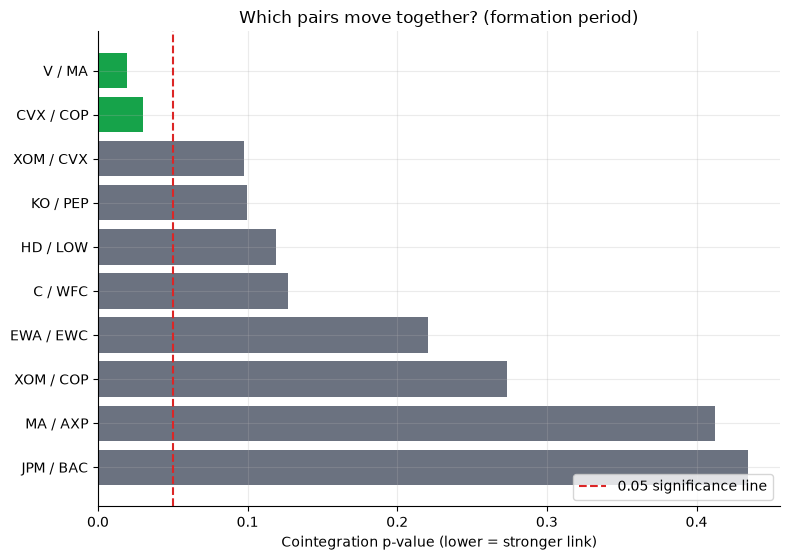

In [4]:
plots.plot_pair_scan(scan);

## 4. Run the strategy on the best pair

In [5]:
stock_a, stock_b = scan.loc[0, 'stock_a'], scan.loc[0, 'stock_b']
result = run_pair(prices[stock_a], prices[stock_b], settings)
print(f'{stock_a} vs {stock_b}, hedge ratio {result.hedge_ratio:.3f}')
{name: round(value, 3) for name, value in result.summary.items()}

V vs MA, hedge ratio 0.825


{'Total return': np.float64(0.049),
 'Annual return': np.float64(0.012),
 'Annual volatility': np.float64(0.038),
 'Sharpe ratio': np.float64(0.335),
 'Max drawdown': np.float64(-0.054),
 'Number of trades': 31,
 'Win rate': np.float64(0.613),
 'Time in market': np.float64(0.399),
 'Buy & hold return': np.float64(0.629)}

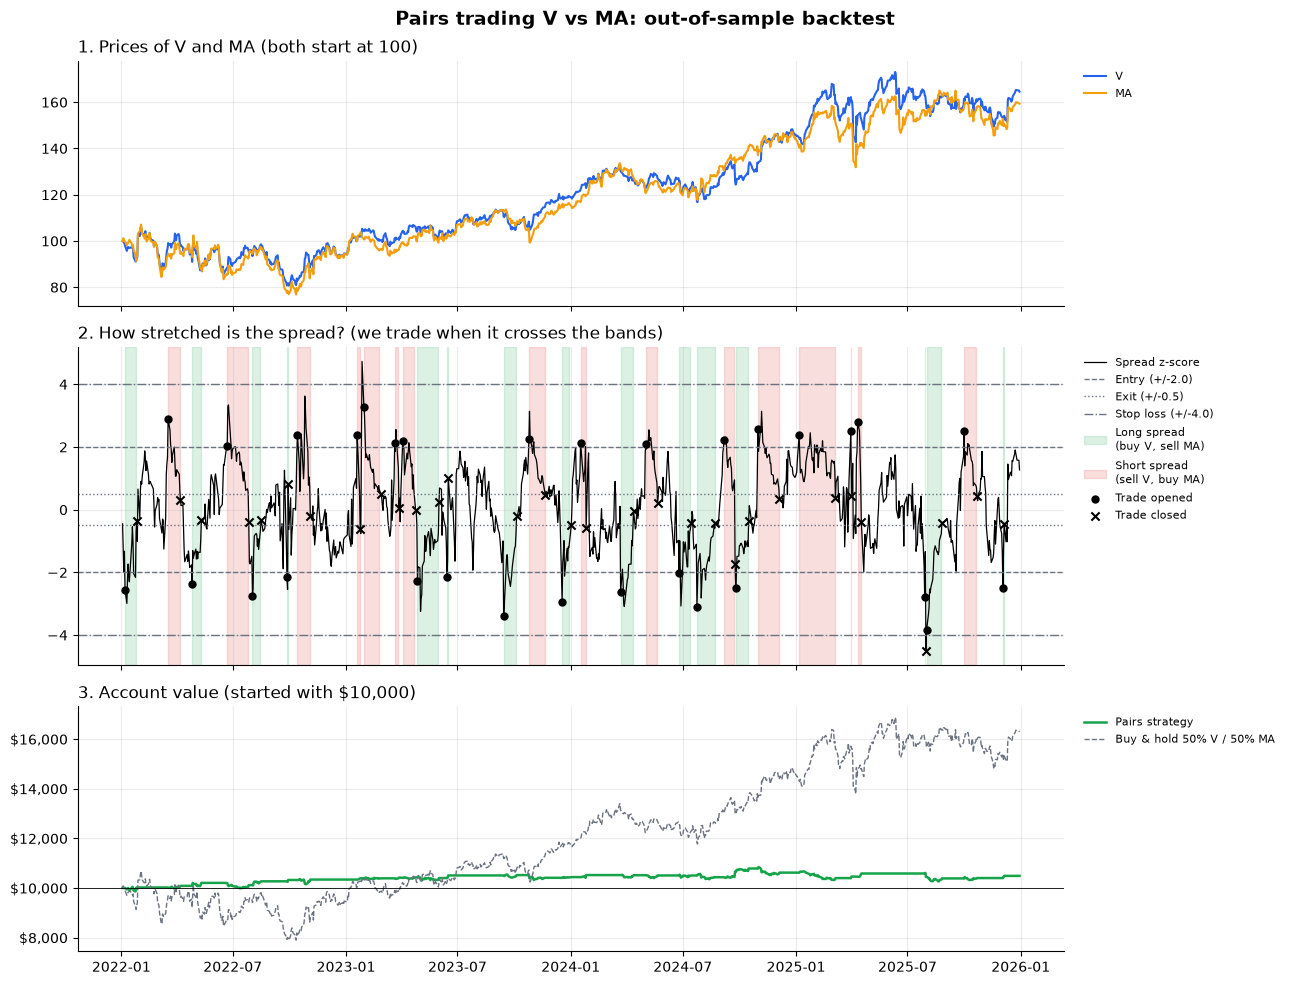

In [6]:
plots.plot_strategy(result.results, result.trades, stock_a, stock_b, settings);

## 5. Every trade

In [7]:
result.trades

,entry_date,exit_date,direction,days_held,return
0,2022-01-07,2022-01-26,Long spread,12,0.001781
1,2022-03-18,2022-04-07,Short spread,14,0.006454
2,2022-04-26,2022-05-11,Long spread,11,0.011848
3,2022-06-21,2022-07-27,Short spread,25,-0.008774
4,2022-08-02,2022-08-16,Long spread,10,0.015221
5,2022-09-27,2022-09-29,Long spread,2,0.005184
6,2022-10-14,2022-11-04,Short spread,15,0.001663
7,2023-01-19,2023-01-24,Short spread,3,0.005054
8,2023-01-30,2023-02-27,Short spread,19,-0.000226
9,2023-03-21,2023-03-28,Short spread,5,0.002691


## 6. Try your own settings
Change any number and re-run the cell.

In [8]:
from dataclasses import replace

my_settings = replace(settings, entry_z=2.5, zscore_window=60)
mine = run_pair(prices[stock_a], prices[stock_b], my_settings)
{name: round(value, 3) for name, value in mine.summary.items()}

{'Total return': np.float64(0.067),
 'Annual return': np.float64(0.016),
 'Annual volatility': np.float64(0.024),
 'Sharpe ratio': np.float64(0.696),
 'Max drawdown': np.float64(-0.024),
 'Number of trades': 12,
 'Win rate': np.float64(0.833),
 'Time in market': np.float64(0.255),
 'Buy & hold return': np.float64(0.629)}